NHL goal replay visualization prototype
A visualization-only notebook for inspecting NHL Edge tracking frames before building a separate annotation workflow.

Design
- Team-coloured player markers with jersey numbers
- Black puck marker
- Short, fading trails
- Game clock and frame index
- Optional scorer highlight
- Fixed rink: draw once, update only the tracking artists
- Bidirectional frame navigation with ipywidgets
The initial test game is 2025020001. This notebook uses the existing processed tracking parquet and does not modify the source data.

1. Imports and paths
Run this notebook from goal-analysis/notebooks/, consistent with the other project notebooks.

In [1]:
%matplotlib widget

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
import ipywidgets as widgets
from IPython.display import display

from sportypy.surfaces.hockey import NHLRink

PROJECT_DIR = Path.cwd().parent
ROOT_DIR = PROJECT_DIR.parent
DATA_DIR = ROOT_DIR / "data" / "processed" / "nhl-tracking-pipeline"

SEASON = "20252026"
GAME_ID = 2025020001

TRACKING_PATH = DATA_DIR / "tracking" / f"{SEASON}.parquet"
GAMES_PATH = DATA_DIR / "games" / f"{SEASON}.parquet"

print("Project:", PROJECT_DIR)
print("Tracking:", TRACKING_PATH, TRACKING_PATH.exists())
print("Games:", GAMES_PATH, GAMES_PATH.exists())


Project: /home/bfriesen/Documents/nhl-analytics/goal-analysis
Tracking: /home/bfriesen/Documents/nhl-analytics/data/processed/nhl-tracking-pipeline/tracking/20252026.parquet True
Games: /home/bfriesen/Documents/nhl-analytics/data/processed/nhl-tracking-pipeline/games/20252026.parquet True


2. Load and inspect the tracking data
The tracking parquet is goal/replay-oriented, so filter to the selected game before doing any plotting. The tracking rows already include sweater_number; we can use (team_id, sweater_number) to identify a player and retain player_id as the stable annotation key.

In [2]:
tracking_columns = [
    "game_id", "event_id", "frame_idx", "seconds_to_goal",
    "period", "time_in_period", "home_team_id", "away_team_id",
    "entity_type", "player_id", "team_id", "team_abbrev", "sweater_number",
    "is_scorer", "x", "y", "x_att", "y_att",
]

tracking = pd.read_parquet(
    TRACKING_PATH,
    filters=[("game_id", "==", GAME_ID)],
    columns=tracking_columns,
)

tracking = tracking.sort_values(["event_id", "frame_idx", "entity_type"]).reset_index(drop=True)

integer_columns = [
    "game_id",
    "event_id",
    "frame_idx",
    "player_id",
    "team_id",
    "sweater_number",
]

for col in integer_columns:
    tracking[col] = pd.to_numeric(
        tracking[col], errors="coerce"
    ).astype("Int64")

print(f"{len(tracking):,} tracking rows")
display(tracking.head())
display(tracking.dtypes.to_frame("dtype"))


9,194 tracking rows


,game_id,event_id,frame_idx,seconds_to_goal,period,time_in_period,home_team_id,away_team_id,entity_type,player_id,team_id,team_abbrev,sweater_number,is_scorer,x,y,x_att,y_att
0,2025020001,258,0,-10.3,1,10:03,13,16,player,8477495,13,FLA,3,False,3.164000,-1.899000,3.164000,-1.899000
1,2025020001,258,0,-10.3,1,10:03,13,16,player,8478859,13,FLA,77,False,-29.733999,-40.551998,-29.733999,-40.551998
2,2025020001,258,0,-10.3,1,10:03,13,16,player,8477409,13,FLA,23,False,-23.209000,-35.527000,-23.209000,-35.527000
3,2025020001,258,0,-10.3,1,10:03,13,16,player,8477935,13,FLA,9,False,-35.004002,-31.167000,-35.004002,-31.167000
4,2025020001,258,0,-10.3,1,10:03,13,16,player,8481519,16,CHI,30,False,-86.230003,-2.595000,-86.230003,-2.595000


,dtype
game_id,Int64
event_id,Int64
frame_idx,Int64
seconds_to_goal,float32
period,int32
time_in_period,str
home_team_id,int32
away_team_id,int32
entity_type,str
player_id,Int64


3. Choose a goal event
Inspect the available events and select one. By default, the notebook uses the first event in the game. Change EVENT_ID after inspecting the table.

In [3]:
event_summary = (
    tracking.groupby("event_id")
    .agg(
        frames=("frame_idx", "nunique"),
        first_frame=("frame_idx", "min"),
        last_frame=("frame_idx", "max"),
        first_seconds_to_goal=("seconds_to_goal", "min"),
        last_seconds_to_goal=("seconds_to_goal", "max"),
        entities=("entity_type", "nunique"),
    )
    .reset_index()
)
display(event_summary)

EVENT_ID = event_summary.loc[0, "event_id"]
print("Selected event:", EVENT_ID)


,event_id,frames,first_frame,last_frame,first_seconds_to_goal,last_seconds_to_goal,entities
0,258,140,0,139,-10.3,3.6,2
1,274,140,0,139,-10.9,3.0,2
2,366,140,0,139,-9.4,4.5,2
3,630,140,0,139,-13.9,0.0,2
4,1101,140,0,139,-9.0,4.9,2


Selected event: 258


In [4]:
event_data = tracking.loc[tracking["event_id"] == EVENT_ID].copy()

# Prefer attack-oriented coordinates when available. These should keep the
# attacking direction consistent across events.
COORD_X, COORD_Y = "x_att", "y_att"

if event_data[[COORD_X, COORD_Y]].notna().sum().min() == 0:
    COORD_X, COORD_Y = "x", "y"

event_data = event_data.dropna(subset=[COORD_X, COORD_Y]).copy()

frames = np.sort(event_data["frame_idx"].unique())
if len(frames) == 0:
    raise ValueError("The selected event has no frames with valid coordinates.")

print(f"{len(frames)} frames: {frames[0]} to {frames[-1]}")
print("Coordinate columns:", COORD_X, COORD_Y)
display(event_data.head())


140 frames: 0 to 139
Coordinate columns: x_att y_att


,game_id,event_id,frame_idx,seconds_to_goal,period,time_in_period,home_team_id,away_team_id,entity_type,player_id,team_id,team_abbrev,sweater_number,is_scorer,x,y,x_att,y_att
0,2025020001,258,0,-10.3,1,10:03,13,16,player,8477495,13,FLA,3,False,3.164000,-1.899000,3.164000,-1.899000
1,2025020001,258,0,-10.3,1,10:03,13,16,player,8478859,13,FLA,77,False,-29.733999,-40.551998,-29.733999,-40.551998
2,2025020001,258,0,-10.3,1,10:03,13,16,player,8477409,13,FLA,23,False,-23.209000,-35.527000,-23.209000,-35.527000
3,2025020001,258,0,-10.3,1,10:03,13,16,player,8477935,13,FLA,9,False,-35.004002,-31.167000,-35.004002,-31.167000
4,2025020001,258,0,-10.3,1,10:03,13,16,player,8481519,16,CHI,30,False,-86.230003,-2.595000,-86.230003,-2.595000


4. Player identity lookup
The jersey number is useful for visual inspection and manual labeling. The player ID remains the durable identifier used in the eventual training data.

We build a lookup keyed by (team_id, sweater_number). If the tracking data contains conflicting mappings, the cell reports them rather than silently choosing one.

In [5]:
players = event_data.loc[event_data["entity_type"].str.lower().eq("player")].copy()

identity_columns = ["team_id", "sweater_number", "player_id", "team_abbrev"]
identity = players[identity_columns].drop_duplicates()

mapping_counts = (
    identity.groupby(["team_id", "sweater_number"])["player_id"]
    .nunique()
)
conflicts = mapping_counts[mapping_counts > 1]

if not conflicts.empty:
    display(conflicts.to_frame("distinct_player_ids"))
    raise ValueError("A team/jersey combination maps to multiple player IDs in this event.")

player_lookup = (
    identity.drop_duplicates(["team_id", "sweater_number"])
    .set_index(["team_id", "sweater_number"])["player_id"]
    .to_dict()
)

display(identity.sort_values(["team_id", "sweater_number"]).reset_index(drop=True))
print(f"{len(player_lookup)} team/jersey -> player ID mappings")


player_metadata = pd.read_parquet(DATA_DIR / "players.parquet")

player_metadata["player_name"] = (
    player_metadata["firstName"] + " " + player_metadata["lastName"]
)

identity = identity.merge(
    player_metadata[["playerId", "player_name", "positionCode"]],
    left_on="player_id",
    right_on="playerId",
    how="left",
).drop(columns="playerId")

display(identity.sort_values(["team_id", "sweater_number"]).reset_index(drop=True))

,team_id,sweater_number,player_id,team_abbrev
0,13,3,8477495,FLA
1,13,9,8477935,FLA
2,13,23,8477409,FLA
3,13,63,8473419,FLA
4,13,72,8475683,FLA
5,13,77,8478859,FLA
6,16,30,8481519,CHI
7,16,44,8482176,CHI
8,16,55,8484783,CHI
9,16,59,8477479,CHI


13 team/jersey -> player ID mappings


,team_id,sweater_number,player_id,team_abbrev,player_name,positionCode
0,13,3,8477495,FLA,Seth Jones,D
1,13,9,8477935,FLA,Sam Bennett,C
2,13,23,8477409,FLA,Carter Verhaeghe,C
3,13,63,8473419,FLA,Brad Marchand,L
4,13,72,8475683,FLA,Sergei Bobrovsky,G
5,13,77,8478859,FLA,Niko Mikkola,D
6,16,30,8481519,CHI,Spencer Knight,G
7,16,44,8482176,CHI,Wyatt Kaiser,D
8,16,55,8484783,CHI,Artyom Levshunov,D
9,16,59,8477479,CHI,Tyler Bertuzzi,L


5. Inspect one frame before building the replay
This is a quick sanity check for entity types, teams, coordinates, jersey numbers, and scorer flags.

In [6]:
first_frame = event_data.loc[event_data["frame_idx"] == frames[0]].copy()

display(
    first_frame[
        ["frame_idx", "seconds_to_goal", "period", "time_in_period",
         "entity_type", "team_abbrev", "team_id", "sweater_number", "player_id",
         "is_scorer", COORD_X, COORD_Y]
    ].sort_values(["entity_type", "team_id", "sweater_number"])
)


,frame_idx,seconds_to_goal,period,time_in_period,entity_type,team_abbrev,team_id,sweater_number,player_id,is_scorer,x_att,y_att
0,0,-10.3,1,10:03,player,FLA,13,3,8477495,False,3.164000,-1.899000
3,0,-10.3,1,10:03,player,FLA,13,9,8477935,False,-35.004002,-31.167000
2,0,-10.3,1,10:03,player,FLA,13,23,8477409,False,-23.209000,-35.527000
5,0,-10.3,1,10:03,player,FLA,13,63,8473419,False,-42.480000,-12.382000
6,0,-10.3,1,10:03,player,FLA,13,72,8475683,False,88.388000,0.128000
1,0,-10.3,1,10:03,player,FLA,13,77,8478859,False,-29.733999,-40.551998
4,0,-10.3,1,10:03,player,CHI,16,30,8481519,False,-86.230003,-2.595000
8,0,-10.3,1,10:03,player,CHI,16,44,8482176,False,-53.936001,-10.274000
7,0,-10.3,1,10:03,player,CHI,16,55,8484783,False,-58.952999,-32.830002
11,0,-10.3,1,10:03,player,CHI,16,59,8477479,False,-31.853001,-41.000000


6. Replay visualizer
The rink is drawn exactly once in the constructor. Each update changes the offsets/text/visibility of existing artists.

Trail opacity decreases with age. Players are assigned stable marker/text artists for the duration of the selected event. The visualizer does not create or store annotation labels.

In [7]:
import json
from pathlib import Path

colour_path = ROOT_DIR / "data" / "processed" / "nhl_team_colours.json"

with open(colour_path) as f:
    team_data = json.load(f)

# Look up each team's full metadata by NHL team ID.
teams_by_id = {
    int(team["team_id"]): team
    for team in team_data
}

# Primary colour for each team, including the leading '#'.
team_colours_by_id = {
    team_id: team["colors"]["hex"][0]
    for team_id, team in teams_by_id.items()
}

print(f"Loaded colours for {len(team_colours_by_id)} teams.")

Loaded colours for 33 teams.


In [8]:
class ReplayVisualizer:
    def __init__(
        self,
        data,
        frames,
        rink,
        x_col="x_att",
        y_col="y_att",
        trail_frames=6,
        highlight_scorer=True,
        figsize=(12, 6.5),
    ):
        self.data = data.copy()
        self.frames = np.asarray(frames)
        self.x_col = x_col
        self.y_col = y_col
        self.trail_frames = int(trail_frames)
        self.highlight_scorer = highlight_scorer
        self.home_team_id = int(self.data["home_team_id"].dropna().iloc[0])
        self.away_team_id = int(self.data["away_team_id"].dropna().iloc[0])
        self.player_data = self.data.loc[
            self.data["entity_type"].str.lower().eq("player")
        ].copy()
        self.puck_data = self.data.loc[
            self.data["entity_type"].str.lower().eq("puck")
        ].copy()

        # Stable player keys for this event.
        self.player_keys = (
            self.player_data[["team_id", "sweater_number", "player_id", "team_abbrev"]]
            .drop_duplicates()
            .sort_values(["team_id", "sweater_number"])
            .to_dict("records")
        )

        team_ids = self.player_data["team_id"].dropna().unique()

        self.team_colours = {}
        for team_id in team_ids:
            team_id = int(team_id)

            if team_id not in team_colours_by_id:
                raise ValueError(f"No colour data found for team ID {team_id}")

            self.team_colours[team_id] = team_colours_by_id[team_id]

        if self.home_team_id not in self.team_colours:
            raise ValueError(
                f"Home team ID {self.home_team_id} not found in tracking data."
            )

        self.fig, self.ax = plt.subplots(figsize=figsize)
        rink.draw(ax=self.ax)
        self.ax.set_aspect("equal", adjustable="box")
        self.ax.set_title("NHL tracking replay")
        self.clock_text = self.ax.text(
            0.015, 0.985, "", transform=self.ax.transAxes,
            ha="left", va="top", fontsize=11,
            bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=4),
            zorder=20,
        )

        # Create one player marker, jersey label, and trail artist per player.
        self.player_artists = {}
        self.player_trails = {}
        self.player_labels = {}
        self.scorer_rings = {}

        for player in self.player_keys:
            key = (player["team_id"], player["sweater_number"])
            team_id = int(player["team_id"])
            colour = self.team_colours[team_id]

            if team_id == self.home_team_id:
                face_colour = colour
                edge_colour = "white"
                label_colour = "white"
            elif team_id == self.away_team_id:
                face_colour = "white"
                edge_colour = colour
                label_colour = colour
            else:
                raise ValueError(f"Unexpected player team ID: {team_id}")
                
            # Player marker
            marker = self.ax.scatter(
                [], [], s=230, c=[face_colour], edgecolors=edge_colour,
                linewidths=1.5, zorder=103,
            )

            # Separate outer ring, shown only for the scorer
            scorer_ring = self.ax.scatter(
                [], [], s=450, facecolors="none", edgecolors=colour,
                linewidths=2.5, zorder=102,
            )

            # Jersey number
            label = self.ax.text(
                0, 0, str(int(player["sweater_number"])),
                ha="center", va="center", fontsize=8,
                fontweight="bold", color=label_colour, zorder=104,
            )

            # Player trail
            trail = self.ax.scatter(
                [], [], s=[], c=[], marker="o", linewidths=0, zorder=101,
            )

            self.player_artists[key] = marker
            self.player_labels[key] = label
            self.player_trails[key] = trail
            self.scorer_rings[key] = scorer_ring

        # Puck and puck trail.
        self.puck_artist = self.ax.scatter(
            [], [], s=45, c="black", edgecolors="white",
            linewidths=0.7, zorder=106,
        )
        self.puck_trail = self.ax.scatter(
            [], [], s=[], c=[], marker="o", linewidths=0, zorder=102,
        )

        self.current_frame_position = 0
        self.update(0)

    @staticmethod
    def _finite_xy(rows, x_col, y_col):
        rows = rows.dropna(subset=[x_col, y_col])
        if rows.empty:
            return np.empty((0, 2))
        return rows[[x_col, y_col]].to_numpy(dtype=float)

    def _trail(self, rows, frame_position):
        start = max(0, frame_position - self.trail_frames + 1)
        past_frames = self.frames[start:frame_position + 1]
    
        rows = rows.loc[rows["frame_idx"].isin(past_frames)]
        rows = rows.sort_values("frame_idx")

        return self._finite_xy(rows, self.x_col, self.y_col)
        
    def _set_trail(self, artist, xy, base_colour):
        if len(xy) == 0:
            artist.set_offsets(np.empty((0, 2)))
            artist.set_sizes([])
            artist.set_array(None)
            artist.set_facecolors([])
            return
    
        alpha = np.linspace(0.12, 0.65, len(xy))
        rgba = np.tile(to_rgba(base_colour), (len(xy), 1))
        rgba[:, 3] = alpha
    
        sizes = np.linspace(12, 35, len(xy))
    
        artist.set_offsets(xy)
        artist.set_sizes(sizes)
        artist.set_array(None)
        artist.set_facecolors(rgba)
        
    def update(self, frame_position):
        frame_position = int(np.clip(frame_position, 0, len(self.frames) - 1))
        self.current_frame_position = frame_position
        frame_idx = self.frames[frame_position]

        current = self.data.loc[self.data["frame_idx"] == frame_idx]
        current_players = current.loc[
            current["entity_type"].str.lower().eq("player")
        ]

        # Update player positions, labels, scorer outlines, and trails.
        for player in self.player_keys:
            key = (player["team_id"], player["sweater_number"])
            mask = (
                current_players["team_id"].eq(player["team_id"])
                & current_players["sweater_number"].eq(player["sweater_number"])
            )
            row = current_players.loc[mask]

            marker = self.player_artists[key]
            label = self.player_labels[key]
            trail_artist = self.player_trails[key]
            ring = self.scorer_rings[key]
            
            if row.empty:
                marker.set_offsets(np.empty((0, 2)))
                ring.set_offsets(np.empty((0, 2)))
                label.set_visible(False)
                continue
                
            row = row.iloc[0]
            x, y = row[self.x_col], row[self.y_col]
            marker.set_offsets([[x, y]])
            label.set_position((x, y))
            label.set_visible(True)

            is_scorer = bool(row.get("is_scorer", False))

            if self.highlight_scorer and is_scorer:
                ring.set_offsets([[x, y]])
            else:
                ring.set_offsets(np.empty((0, 2)))
                
            history = self.player_data.loc[
                self.player_data["team_id"].eq(player["team_id"])
                & self.player_data["sweater_number"].eq(player["sweater_number"])
            ]
            trail_xy = self._trail(history, frame_position)
            self._set_trail(
                trail_artist, trail_xy,
                self.team_colours[int(player["team_id"])],
            )

        # Update puck and its trail.
        current_puck = current.loc[current["entity_type"].str.lower().eq("puck")]
        if current_puck.empty:
            self.puck_artist.set_offsets(np.empty((0, 2)))
        else:
            puck_row = current_puck.iloc[0]
            self.puck_artist.set_offsets([[puck_row[self.x_col], puck_row[self.y_col]]])

        puck_history = self.puck_data
        puck_xy = self._trail(puck_history, frame_position)
        self._set_trail(self.puck_trail, puck_xy, "black")

        # Prefer the source timestamp if present; otherwise show seconds to goal.
        time_parts = []
        
        if (
            "period" in current.columns
            and "time_in_period" in current.columns
            and current["period"].notna().any()
            and current["time_in_period"].notna().any()
        ):
            period = int(current["period"].dropna().iloc[0])
            game_time = current["time_in_period"].dropna().iloc[0]
            time_parts.append(f"P{period} {game_time}")
        
        if "seconds_to_goal" in current.columns and current["seconds_to_goal"].notna().any():
            seconds = current["seconds_to_goal"].dropna().iloc[0]
            time_parts.append(f"Goal in {-seconds:.1f} s")
        
        time_text = " | ".join(time_parts)
                    
        self.clock_text.set_text(
            f"Frame {frame_idx}  |  {time_text}"
        )
        self.fig.canvas.draw_idle()

    def show(self):
        display(self.fig)


7. Create the replay

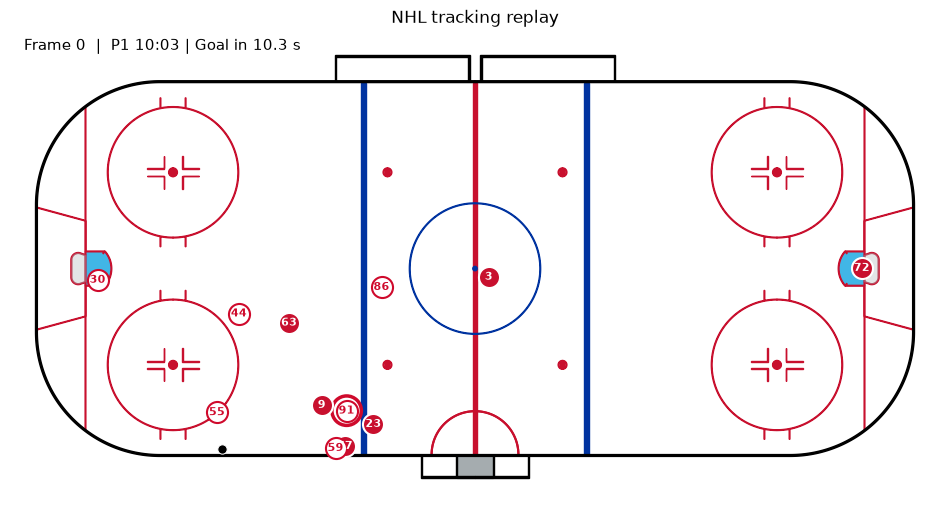

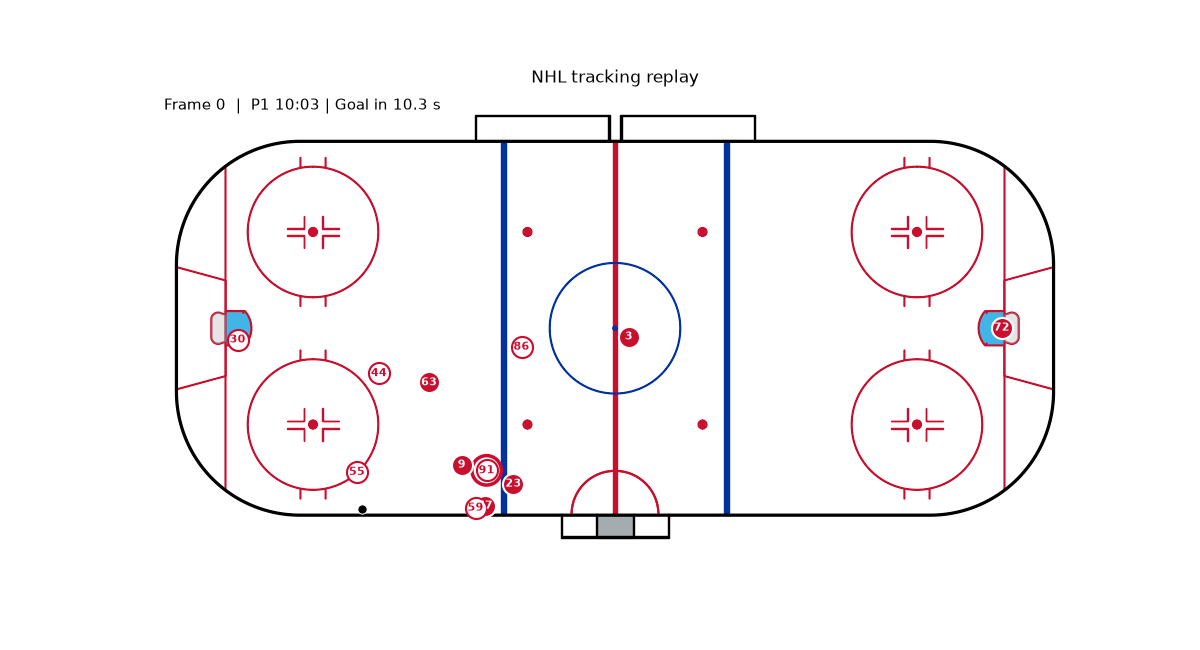

In [9]:
rink = NHLRink()

replay = ReplayVisualizer(
    event_data,
    frames,
    rink,
    x_col=COORD_X,
    y_col=COORD_Y,
    trail_frames=6,
    highlight_scorer=True,
)

replay.show()


8. Frame navigation
The slider jumps directly to any frame. Previous/next buttons move one frame at a time in either direction. continuous_update=False avoids redrawing repeatedly while dragging the slider.

In [10]:
frame_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=len(frames) - 1,
    step=1,
    description="Frame",
    continuous_update=False,
    readout=True,
    layout=widgets.Layout(width="65%"),
)

play_button = widgets.Play(
    value=0,
    min=0,
    max=len(frames) - 1,
    step=1,
    interval=100,  # 10 FPS
    description="Play",
)

widgets.jslink((play_button, "value"), (frame_slider, "value"))

previous_button = widgets.Button(
    description="◀ Previous",
    tooltip="Previous frame",
    layout=widgets.Layout(width="110px"),
)
next_button = widgets.Button(
    description="Next ▶",
    tooltip="Next frame",
    layout=widgets.Layout(width="110px"),
)

def go_to_frame(position):
    position = int(np.clip(position, 0, len(frames) - 1))
    frame_slider.value = position
    replay.update(position)

def on_slider_change(change):
    if change["name"] == "value":
        replay.update(change["new"])

def on_previous(_):
    go_to_frame(frame_slider.value - 1)

def on_next(_):
    go_to_frame(frame_slider.value + 1)

frame_slider.observe(on_slider_change, names="value")
previous_button.on_click(on_previous)
next_button.on_click(on_next)

display(widgets.HBox([
    play_button,
    previous_button,
    frame_slider,
    next_button,
]))

9. Player ID key
This table is deliberately separate from the rink. When manually labeling a play, the human-readable team/jersey combination can be used to resolve the corresponding NHL player ID.

In [11]:
player_key = (
    event_data.loc[event_data["entity_type"].str.lower().eq("player"),
                   ["team_abbrev", "team_id", "sweater_number", "player_id"]]
    .drop_duplicates()
    .sort_values(["team_abbrev", "sweater_number"])
    .reset_index(drop=True)
)
display(player_key)


,team_abbrev,team_id,sweater_number,player_id
0,CHI,16,30,8481519
1,CHI,16,44,8482176
2,CHI,16,55,8484783
3,CHI,16,59,8477479
4,CHI,16,86,8476882
5,CHI,16,91,8483493
6,CHI,16,95,8481624
7,FLA,13,3,8477495
8,FLA,13,9,8477935
9,FLA,13,23,8477409


In [12]:
player = replay.player_keys[0]

history = replay.player_data.loc[
    replay.player_data["team_id"].eq(player["team_id"])
    & replay.player_data["sweater_number"].eq(player["sweater_number"])
]

print("Frames in event:", len(replay.frames))
print("Player observations:", len(history))
print("Unique player frames:", history["frame_idx"].nunique())

print("Current frame position:", replay.current_frame_position)

print(
    "Trail frame indices:",
    replay.frames[
        max(0, replay.current_frame_position - replay.trail_frames + 1):
        replay.current_frame_position + 1
    ],
)

print("Trail coordinates:")
display(history[["frame_idx", replay.x_col, replay.y_col]].tail(10))

Frames in event: 140
Player observations: 140
Unique player frames: 140
Current frame position: 0
Trail frame indices: [0]
Trail coordinates:


,frame_idx,x_att,y_att
1722,130,80.127998,10.766000
1735,131,81.900002,11.401000
1748,132,83.616997,12.162000
1761,133,85.257004,13.061000
1774,134,86.793999,14.114000
1787,135,88.190002,15.340000
1800,136,89.400002,16.743000
1813,137,90.385002,18.299000
1826,138,91.125000,19.959999
1839,139,91.616997,21.677000
